# 40장 · 문서 질문을 화면으로 옮기기

질문 입력칸에 글자를 쓰기만 했는데 검색이 실행되거나 주차 요금을 물었는데 지난번 대출 문서의 출처가 그대로 남을 수 있습니다. 제출했을 때만 검색하고 매번 현재 결과를 새로 저장하는 화면을 만듭니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 질문을 보낸 뒤에만 현재 결과 바꾸기

Streamlit은 위젯을 조작하면 화면 코드를 다시 실행합니다. form으로 묶은 입력은 제출 버튼을 누르는 시점에 함께 받습니다. 새 실행을 지나도 보여 줄 값은 session_state에 남깁니다. 먼저 노트북에서 상태에 어떤 값이 들어가야 하는지 확인합니다.

<!-- motion:form-carbon -->
**입력하다 멈춘 글도 제출한 질문일까요?**

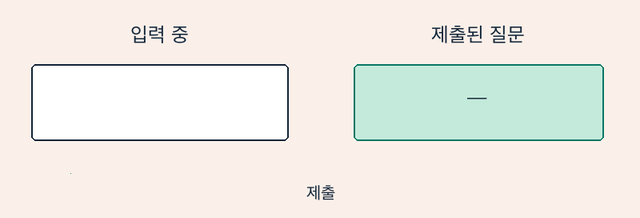

폼의 입력 초안은 제출할 때 복사됩니다. 그전까지 앱이 보관한 마지막 질문은 바뀌지 않습니다.
<!-- /motion -->


### 셀 01 · 새 질문의 근거로 화면 갱신하기

가상의 화면 상태에 대출 답이 보이는 중입니다. 주차 질문을 보냈을 때 이전 출처가 남는지 살펴보세요.

In [1]:
records = [{'id': 'library-1',
  'text': '도서 대출 기간은 14일입니다.',
  'source': '가상 도서관 이용 안내',
  'page': 1},
 {'id': 'library-2',
  'text': '도서관은 월요일에 휴관합니다.',
  'source': '가상 도서관 이용 안내',
  'page': 2},
 {'id': 'library-3',
  'text': '무인 반납함은 24시간 이용할 수 있습니다.',
  'source': '가상 도서관 이용 안내',
  'page': 3}]
terms = ("대출", "휴관", "반납")

def retrieve(question, k=1):
    query = [int(term in question) for term in terms]
    if not any(query):
        return []
    def distance(row):
        vector = [int(term in row["text"]) for term in terms]
        return sum((a-b)**2 for a, b in zip(query, vector)), row["id"]
    return sorted(records, key=distance)[:k]

view = {'question': '대출 기간은?', 'sources': [records[0]]}
def submit(question):
    found = retrieve(question, 1)
    return {'question': question, 'sources': found}

view = submit('주차 요금은?')
print(view)

{'question': '주차 요금은?', 'sources': []}


sources가 빈 목록으로 바뀌었습니다. 기존 화면에 새 답만 덧씌우면 예전 출처가 남을 수 있습니다. 질문과 결과를 한 번에 갱신한 까닭입니다.

## 폼을 작성하고 위젯에 입력 보내기

다음 문자열은 실제 Streamlit 앱 코드입니다. 실습 범위를 입력·출력 위젯으로 좁히려고 대출과 휴관 원문 두 건만 씁니다. 수업 커널에 Streamlit이 있으면 AppTest가 앱을 메모리에서 실행해 위젯을 조작합니다. AppTest는 브라우저 화면을 그리지 않습니다.


### 셀 02 · 두 건의 원문을 담은 폼 작성하기

아래에서 st.form_submit_button 아래의 submitted를 확인하세요. 새 입력의 조회 결과를 last에 저장합니다. form_submit_button 아래에서만 질문을 처리하는 줄을 찾으세요.

In [2]:
app_source = """import streamlit as st

data = {"대출": ("도서 대출 기간은 14일입니다.", "library-1", 1),
        "휴관": ("도서관은 월요일에 휴관합니다.", "library-2", 2)}

st.title("가상 도서관에 질문하기")
with st.form("question_form"):
    question = st.text_input("질문")
    submitted = st.form_submit_button("질문 보내기")
if submitted:
    hit = next((row for word, row in data.items() if word in question), None)
    st.session_state["last"] = hit
    st.session_state["asked"] = True
if st.session_state.get("asked"):
    hit = st.session_state.get("last")
    if hit is None:
        st.info("제공된 자료에서 확인할 수 없습니다.")
    else:
        st.write(hit[0])
        st.caption(f"근거 [{hit[1]}] 가상 도서관 이용 안내 / {hit[2]}쪽")
"""
import ast
app_tree = ast.parse(app_source)
print(app_tree.body[0].names[0].name)

streamlit


streamlit이라는 이름은 소스의 첫 import에서 읽었습니다. 이 셀은 파이썬 구문만 확인합니다. 위젯의 실제 동작은 다음 셀에서 점검합니다. 수업용 화면 주소가 있으면 그 주소를 여세요. 직접 열 때는 이 셀 아래의 파일을 받은 뒤 수업 환경에서 python -m streamlit run chapter40_form.py 명령을 실행하세요. 같은 대화에서 대출 질문 다음에 주차 질문을 제출하고 이전 출처가 사라지는지 확인하세요.

<p><a download="chapter40_form.py" href="">셀에 나온 Streamlit 화면 파일 받기</a></p>

### 셀 03 · Streamlit 커널에서 대출 질문 제출하기

Streamlit이 설치된 수업 커널에서는 첫 입력칸과 제출 버튼을 실제로 조작합니다. 설치 여부에 따라 출력이 달라집니다.

AppTest는 Jupyter 출력에서 폼에 값을 넣고 제출 동작을 확인합니다. 서비스 화면을 수업에서 함께 열었다면 ‘대출’을 제출한 다음 ‘주차’를 제출해 보세요. 두 번째 답에 첫 질문의 출처가 남아 있는지 확인합니다. 설치 안내만 출력된 커널에서는 폼 동작을 관찰한 것이 아닙니다.

In [3]:
from importlib.util import find_spec
if find_spec('streamlit') is None:
    print('Streamlit이 설치된 수업 커널에서 폼 실습을 실행하세요.')
else:
    from streamlit.testing.v1 import AppTest
    app = AppTest.from_string(app_source).run()
    app.text_input[0].set_value('대출 기간은?')
    app.button[0].click().run()
    assert not app.exception
    print(app.markdown[0].value, app.caption[0].value)

Streamlit이 설치된 수업 커널에서 폼 실습을 실행하세요.


설치된 환경에서는 대출 기간과 1쪽 출처가 표시돼야 합니다. 설치 안내가 나온 경우 실제 앱 실행은 남아 있습니다. 위에서 확인한 상태 갱신 실습은 그대로 마칠 수 있습니다.

### 과제 04 · 휴관 질문의 표시 문구 만들기

submit으로 휴관 자료를 찾아 제목과 쪽수가 보이는 출처 문구를 작성하세요.

In [4]:
# 휴관 자료 하나에서 source와 page를 꺼내세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>current = submit(&#x27;휴관일은?&#x27;)
source = current[&#x27;sources&#x27;][0]
print(f&quot;{source[&#x27;source&#x27;]} / {source[&#x27;page&#x27;]}쪽&quot;)</code></pre>
<p>실행 결과</p><pre><code>가상 도서관 이용 안내 / 2쪽</code></pre>
<p>2쪽이라는 위치가 나옵니다. 화면에서 링크나 문구를 만들 때 목록의 순번을 쪽수로 쓰면 원문을 찾아갈 수 없습니다.</p>
</details>

## 돌아보기

정상 답 뒤에 자료 없는 질문을 보내 출처가 지워지는지 확인하세요. 웹 수업 화면까지 점검할 때는 폼 제출 전후와 화면을 다시 그린 뒤를 나누어 보세요.